NAME: SIVASAKTHI
ROLL NO: 24BAD112
EXPERIMENT: IMPLEMENTATION OF AUTOENCODER
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

PART A: DATASET INFORMATION
Training Images Shape: (60000, 28, 28)
Testing Images Shape: (10000, 28, 28)
Number of Training Images: 60000
Number of Testing Images: 10000
Image Dimensions: (28, 28)


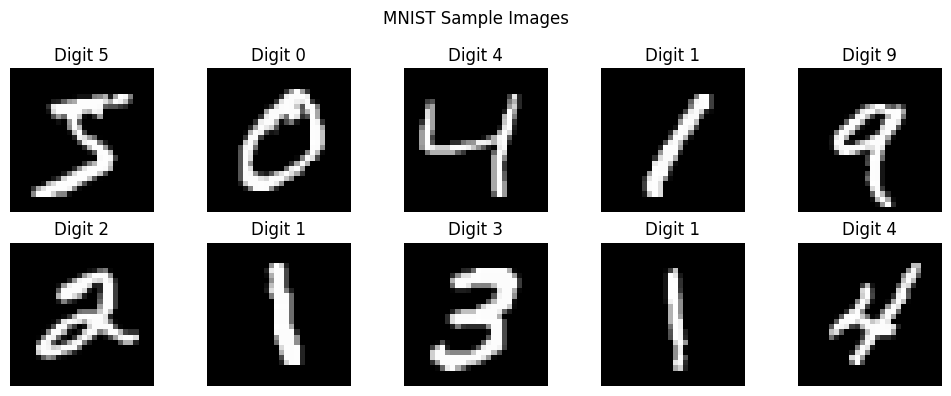


After Preprocessing
Training Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0

ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Latent_Layer (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)


Training Autoencoder...
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - loss: 0.2328 - val_loss: 0.1492
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1325 - val_loss: 0.1187
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1146 - val_loss: 0.1089
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1073 - val_loss: 0.1037
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1031 - val_loss: 0.1000
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1001 - val_loss: 0.0980
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0980 - val_loss: 0.0958
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0961 - val_loss: 0.0942
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0948 - val_loss: 0.0930
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0937 - val_loss: 0.0921

Training Completed Successfully


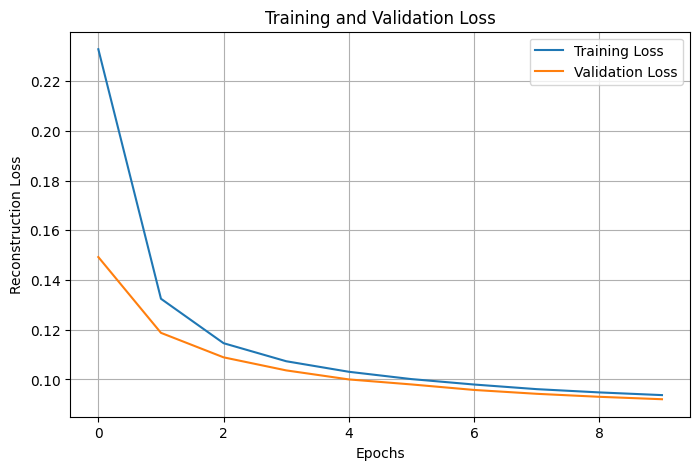

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

PART D: DIMENSIONALITY REDUCTION
Original Input Dimension: 784
Latent Dimension: 32
Latent Feature Shape: (10000, 32)
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Reconstructed Images Shape: (10000, 784)


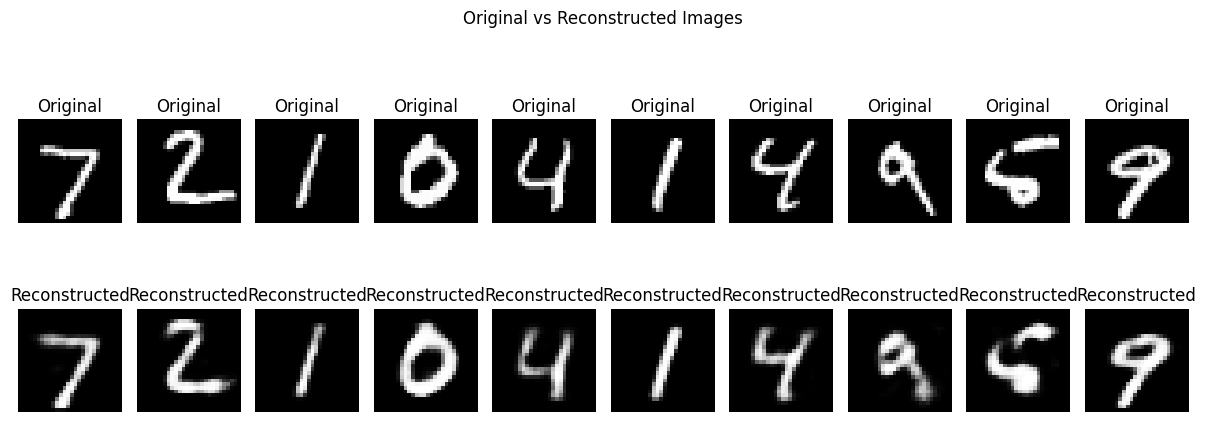


MODEL EVALUATION
Final Test Reconstruction Loss: 0.09205862134695053


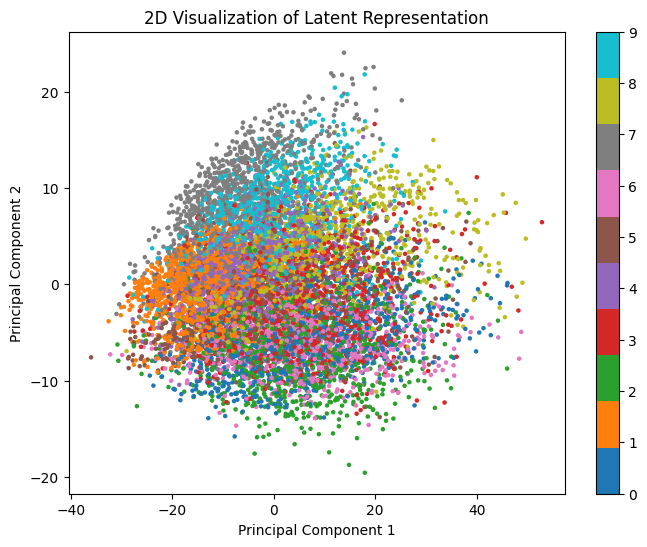


All Models Saved Successfully

RESULT:
Autoencoder implemented and trained successfully.
Input dimension reduced from 784 to 32.
Original images reconstructed successfully.
Reconstruction loss evaluated successfully.


In [1]:

print("NAME: SIVASAKTHI")
print("ROLL NO: 24BAD112")
print("EXPERIMENT: IMPLEMENTATION OF AUTOENCODER")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from sklearn.decomposition import PCA

# PART A: DATASET PREPARATION

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("\nPART A: DATASET INFORMATION")
print("Training Images Shape:", x_train.shape)
print("Testing Images Shape:", x_test.shape)
print("Number of Training Images:", len(x_train))
print("Number of Testing Images:", len(x_test))
print("Image Dimensions:", x_train[0].shape)

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit " + str(y_train[i]))
    plt.axis('off')

plt.suptitle("MNIST Sample Images")
plt.tight_layout()
plt.show()

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("\nAfter Preprocessing")
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())


# PART B: IMPLEMENTING ENCODER AND DECODER

input_layer = Input(shape=(784,), name="Input_Layer")

encoded = Dense(128, activation='relu', name="Encoder_Hidden")(input_layer)

latent = Dense(32, activation='relu', name="Latent_Layer")(encoded)

encoder = Model(input_layer, latent, name="Encoder")

print("\nENCODER SUMMARY")
encoder.summary()

latent_input = Input(shape=(32,), name="Latent_Input")

decoded = Dense(128, activation='relu', name="Decoder_Hidden")(latent_input)

output_layer = Dense(784, activation='sigmoid', name="Output_Layer")(decoded)

decoder = Model(latent_input, output_layer, name="Decoder")

print("\nDECODER SUMMARY")
decoder.summary()

autoencoder_input = Input(shape=(784,))

encoded_output = encoder(autoencoder_input)

decoded_output = decoder(encoded_output)

autoencoder = Model(autoencoder_input, decoded_output, name="Autoencoder")

print("\nAUTOENCODER SUMMARY")
autoencoder.summary()


# PART C: COMPILING AND TRAINING

autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

print("\nTraining Autoencoder...")

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

print("\nTraining Completed Successfully")


# TRAINING AND VALIDATION LOSS GRAPH

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Reconstruction Loss")

plt.legend()

plt.grid()

plt.show()


# PART D: DIMENSIONALITY REDUCTION

latent_features = encoder.predict(x_test)

print("\nPART D: DIMENSIONALITY REDUCTION")

print("Original Input Dimension:", x_test.shape[1])

print("Latent Dimension:", latent_features.shape[1])

print("Latent Feature Shape:", latent_features.shape)


# RECONSTRUCTING IMAGES

reconstructed_images = decoder.predict(latent_features)

print("Reconstructed Images Shape:", reconstructed_images.shape)


# ORIGINAL VS RECONSTRUCTED IMAGES

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 10, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    plt.title("Original")

    plt.axis('off')

    plt.subplot(2, 10, i + 11)

    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')

    plt.title("Reconstructed")

    plt.axis('off')

plt.suptitle("Original vs Reconstructed Images")

plt.tight_layout()

plt.show()


# RECONSTRUCTION LOSS EVALUATION

test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)

print("\nMODEL EVALUATION")

print("Final Test Reconstruction Loss:", test_loss)


# PCA VISUALIZATION OF LATENT FEATURES

pca = PCA(n_components=2)

latent_2d = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))

plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test,
    cmap='tab10',
    s=5
)

plt.colorbar()

plt.title("2D Visualization of Latent Representation")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.show()


# SAVE TRAINED MODELS

autoencoder.save("autoencoder_mnist.keras")

encoder.save("encoder_mnist.keras")

decoder.save("decoder_mnist.keras")

print("\nAll Models Saved Successfully")

print("\nRESULT:")
print("Autoencoder implemented and trained successfully.")
print("Input dimension reduced from 784 to 32.")
print("Original images reconstructed successfully.")
print("Reconstruction loss evaluated successfully.")
